
**Curso: modelos de aprendizaje**

**UNIDAD 2**


---

*   NOMBRE:
*   NO CONTROL:



In [1]:
# Montar Google Drive (solo aplica en Google Colab; si se ejecuta en otro entorno se omite)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('No se está ejecutando en Google Colab: se omite el montaje de Drive.')


No se está ejecutando en Google Colab: se omite el montaje de Drive.


In [2]:
import os
DIR = "/content/drive/MyDrive/CLASES/AGO-DIC 2025/MOEDLOS DE APRENDIZAJE/unidad 2/actividad RegresionLogistica"
if os.path.isdir(DIR):
    os.chdir(DIR)   # se cambia al directorio donde está data.csv
else:
    print('No se encontró la carpeta de Drive; se usa el directorio actual:', os.getcwd())


No se encontró la carpeta de Drive; se usa el directorio actual: /mnt/user-data/uploads


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías para preprocesamiento e ing de características
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder,StandardScaler, OrdinalEncoder,FunctionTransformer

# Librerías para la canalización
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline

# Librerías para la regresión
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_squared_error, r2_score, confusion_matrix, precision_score,recall_score,accuracy_score
from sklearn.decomposition import PCA

from sklearn.preprocessing import PolynomialFeatures

---

## **<font color=" #895cf9">Explica brevemente el uso de las librerias del segmento de codigo anterior, haciendo uso de la siguiente tabla</font>**


| Library | Explanation  |
|----------|--------------|
|**import pandas as pd**| Lectura, manipulación y análisis de datos tabulares mediante `DataFrame` y `Series` (leer el .csv, `set_index`, `describe`, `drop`, `value_counts`, etc.). |
|**import numpy as np**| Operaciones matemáticas y numéricas sobre arreglos (por ejemplo `np.sqrt` y la selección de tipos numéricos con `np.number`). |
|**import matplotlib.pyplot as plt**| Creación de gráficas base (histogramas, boxplots, subplots); sobre ella se apoyan otras librerías de visualización. |
|**import seaborn as sns**| Visualización estadística de alto nivel: `countplot`, `heatmap` (mapa de calor de correlaciones) y `pairplot` (matriz de dispersión). |
|**from sklearn.impute import SimpleImputer**| Rellena valores faltantes con una estrategia (media, mediana, moda o constante). Aquí no se requiere porque el dataset no tiene nulos. |
|**from sklearn.preprocessing import MinMaxScaler**| Escala cada variable al intervalo [0, 1] usando el mínimo y el máximo. |
|**from sklearn.preprocessing import OneHotEncoder**| Convierte variables categóricas en columnas binarias (0/1), una por categoría. |
|**from sklearn.preprocessing import StandardScaler**| Estandariza las variables (media 0 y desviación estándar 1). |
|**from sklearn.preprocessing import OrdinalEncoder**| Codifica categorías como números enteros respetando un orden. |
|**from sklearn.preprocessing import FunctionTransformer**| Convierte cualquier función (por ejemplo `np.sqrt`) en un transformador compatible con pipelines. |
|**from sklearn.compose import ColumnTransformer**| Aplica transformaciones distintas a subconjuntos de columnas (eliminar, escalar, transformar) y concatena el resultado. |
|**from sklearn.compose import make_column_selector**| Selecciona columnas automáticamente por tipo de dato o por patrón de nombre. |
|**from sklearn.pipeline import make_pipeline**| Encadena pasos (preprocesamiento + modelo) en un solo objeto con `fit` y `predict`; evita fugas de datos entre entrenamiento y prueba. |
|**from sklearn.linear_model import LinearRegression**| Modelo de regresión lineal para predecir una variable continua. |
|**from sklearn.linear_model import LogisticRegression**| Modelo de clasificación que estima la probabilidad de pertenecer a una clase (aquí: benigno `B` o maligno `M`). |
|**from sklearn.metrics import mean_squared_error, r2_score**| Métricas de regresión: error cuadrático medio y coeficiente de determinación R². |
|**from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score**| Métricas de clasificación: matriz de confusión, precisión, sensibilidad (recall) y exactitud (accuracy). |
|**from sklearn.decomposition import PCA**| Análisis de componentes principales: reduce dimensiones y elimina la multicolinealidad creando componentes no correlacionados. |
|**from sklearn.preprocessing import PolynomialFeatures**| Genera términos polinomiales e interacciones entre variables para modelar relaciones no lineales. |
|**from sklearn.model_selection import train_test_split** *(se importa en la sección 5a)*| Divide el conjunto de datos en entrenamiento y prueba (aquí 80:20). |

---


In [4]:
#lectura del .csv con pandas
data_df = pd.read_csv('data.csv')
data_df.head()


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# **Parte 1**. EDA

Haz que el `id` sea el índice del dataframe y efectúa una exploración inicial de los datos a través de:

In [5]:
#utilice funcion .set_index()
#Guarde los cambios con inplace=True

#-----------------------------------------------------
#Escriba su codigo
data_df.set_index('id', inplace=True)
#-----------------------------------------------------


In [6]:
data_df


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.4630,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.0750,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820




1a) Estadísticas descriptivas para todas las variables del dataframe.

In [7]:
#.describe para variables Numericas
#-----------------------------------------------------
data_df.describe()
#-----------------------------------------------------


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [8]:
#.describe() para variable categoricas
#-----------------------------------------------------
data_df.select_dtypes(exclude=np.number).describe()
#-----------------------------------------------------


,diagnosis
count,569
unique,2
top,B
freq,357


1b) Valores únicos por variable para identificar posibles variables categóricas.

In [9]:
# Se hace una lista de variables numéricas y otra de categóricas.

#-----------------------------------------------------
num_cols = data_df.select_dtypes(include=np.number).columns.tolist() #para variables numericas
cat_cols = data_df.select_dtypes(exclude=np.number).columns.tolist() #para variables Categoricas
#-----------------------------------------------------

In [10]:
# Valores únicos por variable (una variable con pocos valores únicos es candidata a ser categórica)
data_df.nunique()


diagnosis                    2
radius_mean                456
texture_mean               479
perimeter_mean             522
area_mean                  539
smoothness_mean            474
compactness_mean           537
concavity_mean             537
concave points_mean        542
symmetry_mean              432
fractal_dimension_mean     499
radius_se                  540
texture_se                 519
perimeter_se               533
area_se                    528
smoothness_se              547
compactness_se             541
concavity_se               533
concave points_se          507
symmetry_se                498
fractal_dimension_se       545
radius_worst               457
texture_worst              511
perimeter_worst            514
area_worst                 544
smoothness_worst           411
compactness_worst          529
concavity_worst            539
concave points_worst       492
symmetry_worst             500
fractal_dimension_worst    535
dtype: int64

In [11]:
# Recuento de cada categoría única en las variables categóricas
for col in cat_cols:
    print(data_df[col].value_counts())
    print()
    print(data_df[col].value_counts(normalize=True).round(3))


diagnosis
B    357
M    212
Name: count, dtype: int64

diagnosis
B    0.627
M    0.373
Name: proportion, dtype: float64


1c) Búsqueda de valores faltantes.

In [12]:
#Explica cada linea de codigo
print('Número valores faltantes: ')                      # encabezado del reporte
for col in data_df.columns:                              # recorre cada columna del dataframe
  valor=sum(data_df[col].isna())                         # isna() marca con True los nulos; sum() los cuenta
  porcentaje=data_df[col].isna().mean()*100              # la media de los True/False es la proporción de nulos; x100 = porcentaje
  print('{}:{}: porcentaje :{}'.format(col,valor,porcentaje))   # imprime columna, cantidad de nulos y porcentaje


Número valores faltantes: 
diagnosis:0: porcentaje :0.0
radius_mean:0: porcentaje :0.0
texture_mean:0: porcentaje :0.0
perimeter_mean:0: porcentaje :0.0
area_mean:0: porcentaje :0.0
smoothness_mean:0: porcentaje :0.0
compactness_mean:0: porcentaje :0.0
concavity_mean:0: porcentaje :0.0
concave points_mean:0: porcentaje :0.0
symmetry_mean:0: porcentaje :0.0
fractal_dimension_mean:0: porcentaje :0.0
radius_se:0: porcentaje :0.0
texture_se:0: porcentaje :0.0
perimeter_se:0: porcentaje :0.0
area_se:0: porcentaje :0.0
smoothness_se:0: porcentaje :0.0
compactness_se:0: porcentaje :0.0
concavity_se:0: porcentaje :0.0
concave points_se:0: porcentaje :0.0
symmetry_se:0: porcentaje :0.0
fractal_dimension_se:0: porcentaje :0.0
radius_worst:0: porcentaje :0.0
texture_worst:0: porcentaje :0.0
perimeter_worst:0: porcentaje :0.0
area_worst:0: porcentaje :0.0
smoothness_worst:0: porcentaje :0.0
compactness_worst:0: porcentaje :0.0
concavity_worst:0: porcentaje :0.0
concave points_worst:0: porcentaje :

1d) Diagrama de barras para determinar la frecuencia de los diagnósticos (cantidad de observaciones con resultado benigno y maligno)

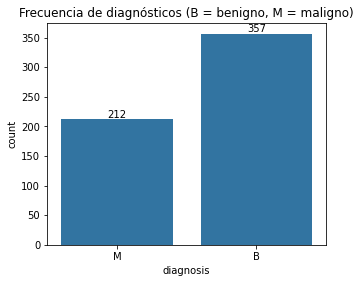

In [13]:
#utilice sns.countplot()
#-----------------------------------------------------
plt.figure(figsize=(5,4))
ax = sns.countplot(x='diagnosis', data=data_df)
ax.set_title('Frecuencia de diagnósticos (B = benigno, M = maligno)')
ax.bar_label(ax.containers[0])      # muestra el conteo sobre cada barra
plt.show()
#-----------------------------------------------------


2. Como hay tres valores relacionados con la misma característica (`mean`, `se` y `worst`) es muy probable que exista multicolinealidad en el conjunto.

La multicolinealidad en regresión es una condición que ocurre cuando algunas variables predictoras están fuertemente correlacionadas entre sí, de tal manera que si se incluyen simultáneamente en un modelo, impiden explicar de manera correcta el efecto que cada una tiene sobre la variable respuesta. Existen muchas formas de analizar si hay colinealidad en los modelos, una de ellas es el alto coeficiente de correlación entre variables.

Para observar este efecto, elabora un mapa de calor que cuantifique la correlación de las variables numéricas en el dataframe.

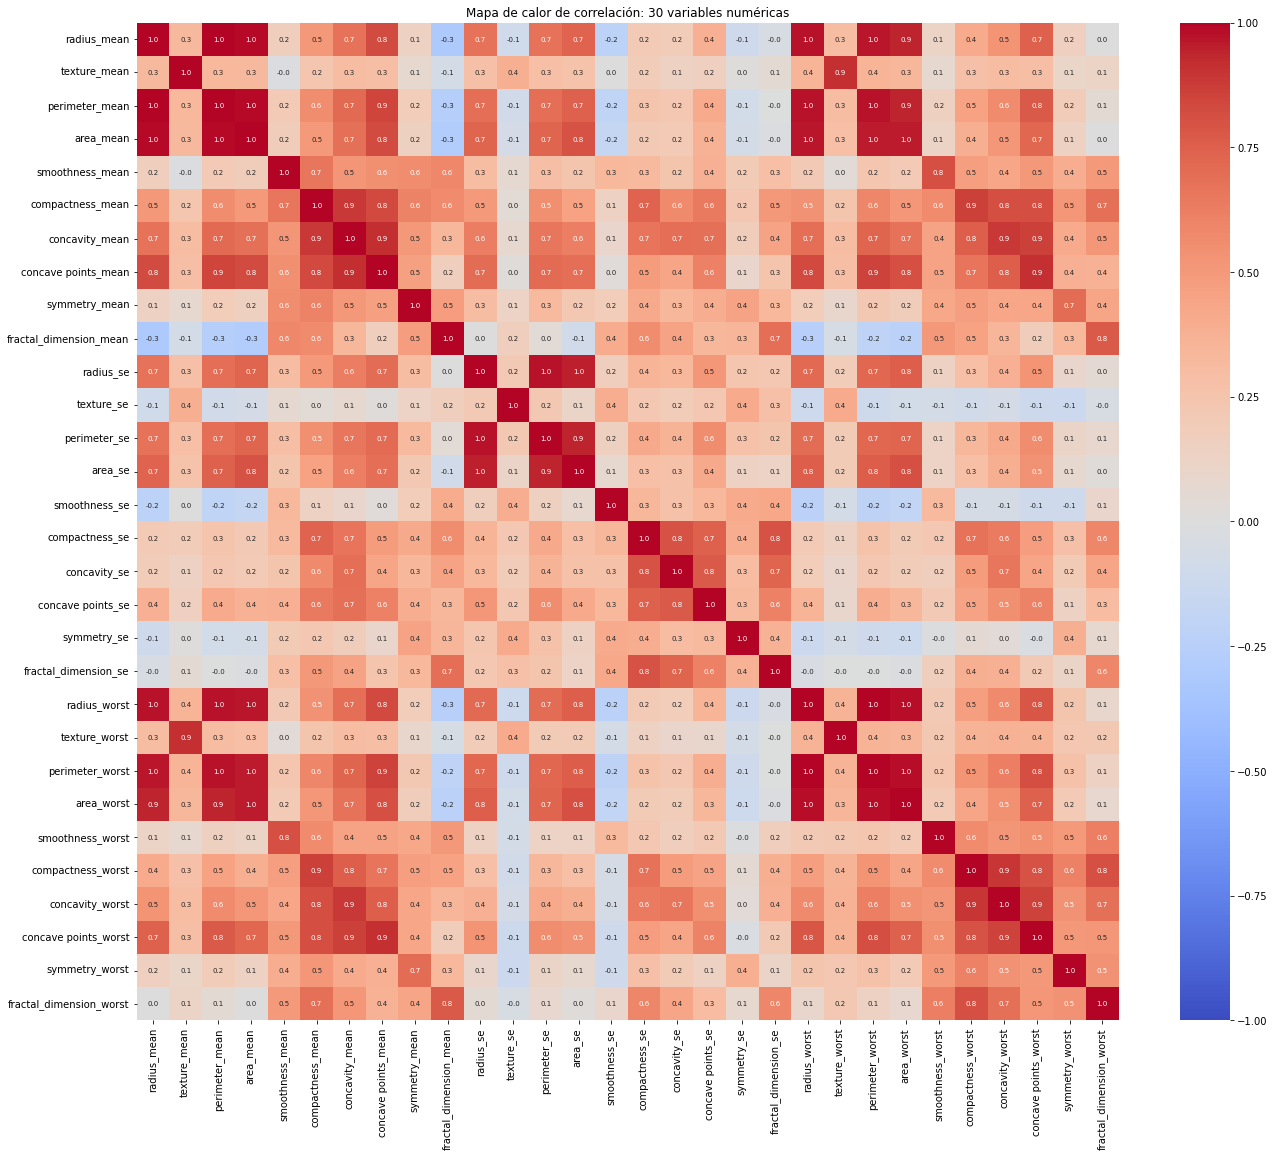

In [14]:
numeric_df = data_df.select_dtypes(include=[float, int])

#-----------------------------------------------------
plt.figure(figsize=(22,18))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.1f', annot_kws={'size':7}, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Mapa de calor de correlación: 30 variables numéricas')
plt.show()
#-----------------------------------------------------


Si te fijas en los valores de correlación entre las variables `_mean` y `_worst` es evidente la multicolinearidad.

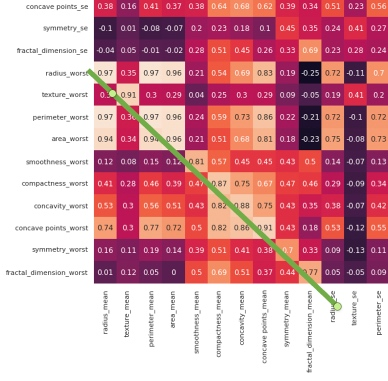

Por ejemplo, la columna `radius_mean` tiene una correlación de 0.97 con la columna `radius_worst`. Esto es algo inevitable, porque las columnas "peores" son esencialmente solo un subconjunto de las columnas "medias".

Para solucionar el problema numérico de la multicolinealidad, tradicionalmente se recurre a eliminar variables o efectuar análisis de componentes principales (PCA) con las `X`’s y usar los componentes como variables independientes en un modelo final.

Conduciremos esta actividad en esos dos sentidos.


# **Parte 2**. Modelo con eliminación de variables altamente correlacionadas  

Elimina las variables altamente correlacionadas:

3a) Ahora que sabes que las variables `_mean` y `_worst` tienen correlación alta, hay que quitar del dataframe un conjunto. Borra las columnas `_worst`.

In [15]:
#-----------------------------------------------------
#Elimine TODAS las columnas _worst
cols_worst = [col for col in data_df.columns if col.endswith('_worst')]
#-----------------------------------------------------

#para borrar las columnas _worst
new_data_df = data_df.drop(columns=cols_worst)

#-----------------------------------------------------
#Convierte new_data_df en Dataframe usando .DataFrame() de la libreria de pandas
new_data_df = pd.DataFrame(new_data_df)
#-----------------------------------------------------
print(new_data_df.shape)
new_data_df.head()


(569, 21)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115


En las graficas de dispersion, los patrones lineales en los diagramas de dispersion se refieren a la relacion entre dos variables que sigue una tendencia aproximadamente en linea recta, ya sea en direccion ascendente o descentende

* **Patron lineal positivo**: Si la linea se inclina hacia arriba (de izquierda a derecha), indica que hay una relacion directa entre las variables: cuando la variable aumenta, la otra tambien lo hace, es decir, CORRELACION POSITIVA

* **Patron lineal negativo**: si la linea se incluna hacia abajo (de izquierda a derecha), indica quue cuando una variable aumenta, la otra disminuye, es decir, CORRELACION NEGATIVA

* **Patron lineal perfecto**, si los puntos siguen una linea recta perfecta, la relacion entre las variables es exactamente lineal, sin desviaciones.


3b. Entre las variables `_mean`, identifica patrones lineales con diagramas de dispersión usando:

    sns.pairplot(data=nuevo_df[['radius_mean',
        'texture_mean',
        'perimeter_mean',
        'area_mean',
        'smoothness_mean',
        'compactness_mean',
        'concavity_mean',
        'concave points_mean',
        'symmetry_mean',
        'fractal_dimension_mean']])



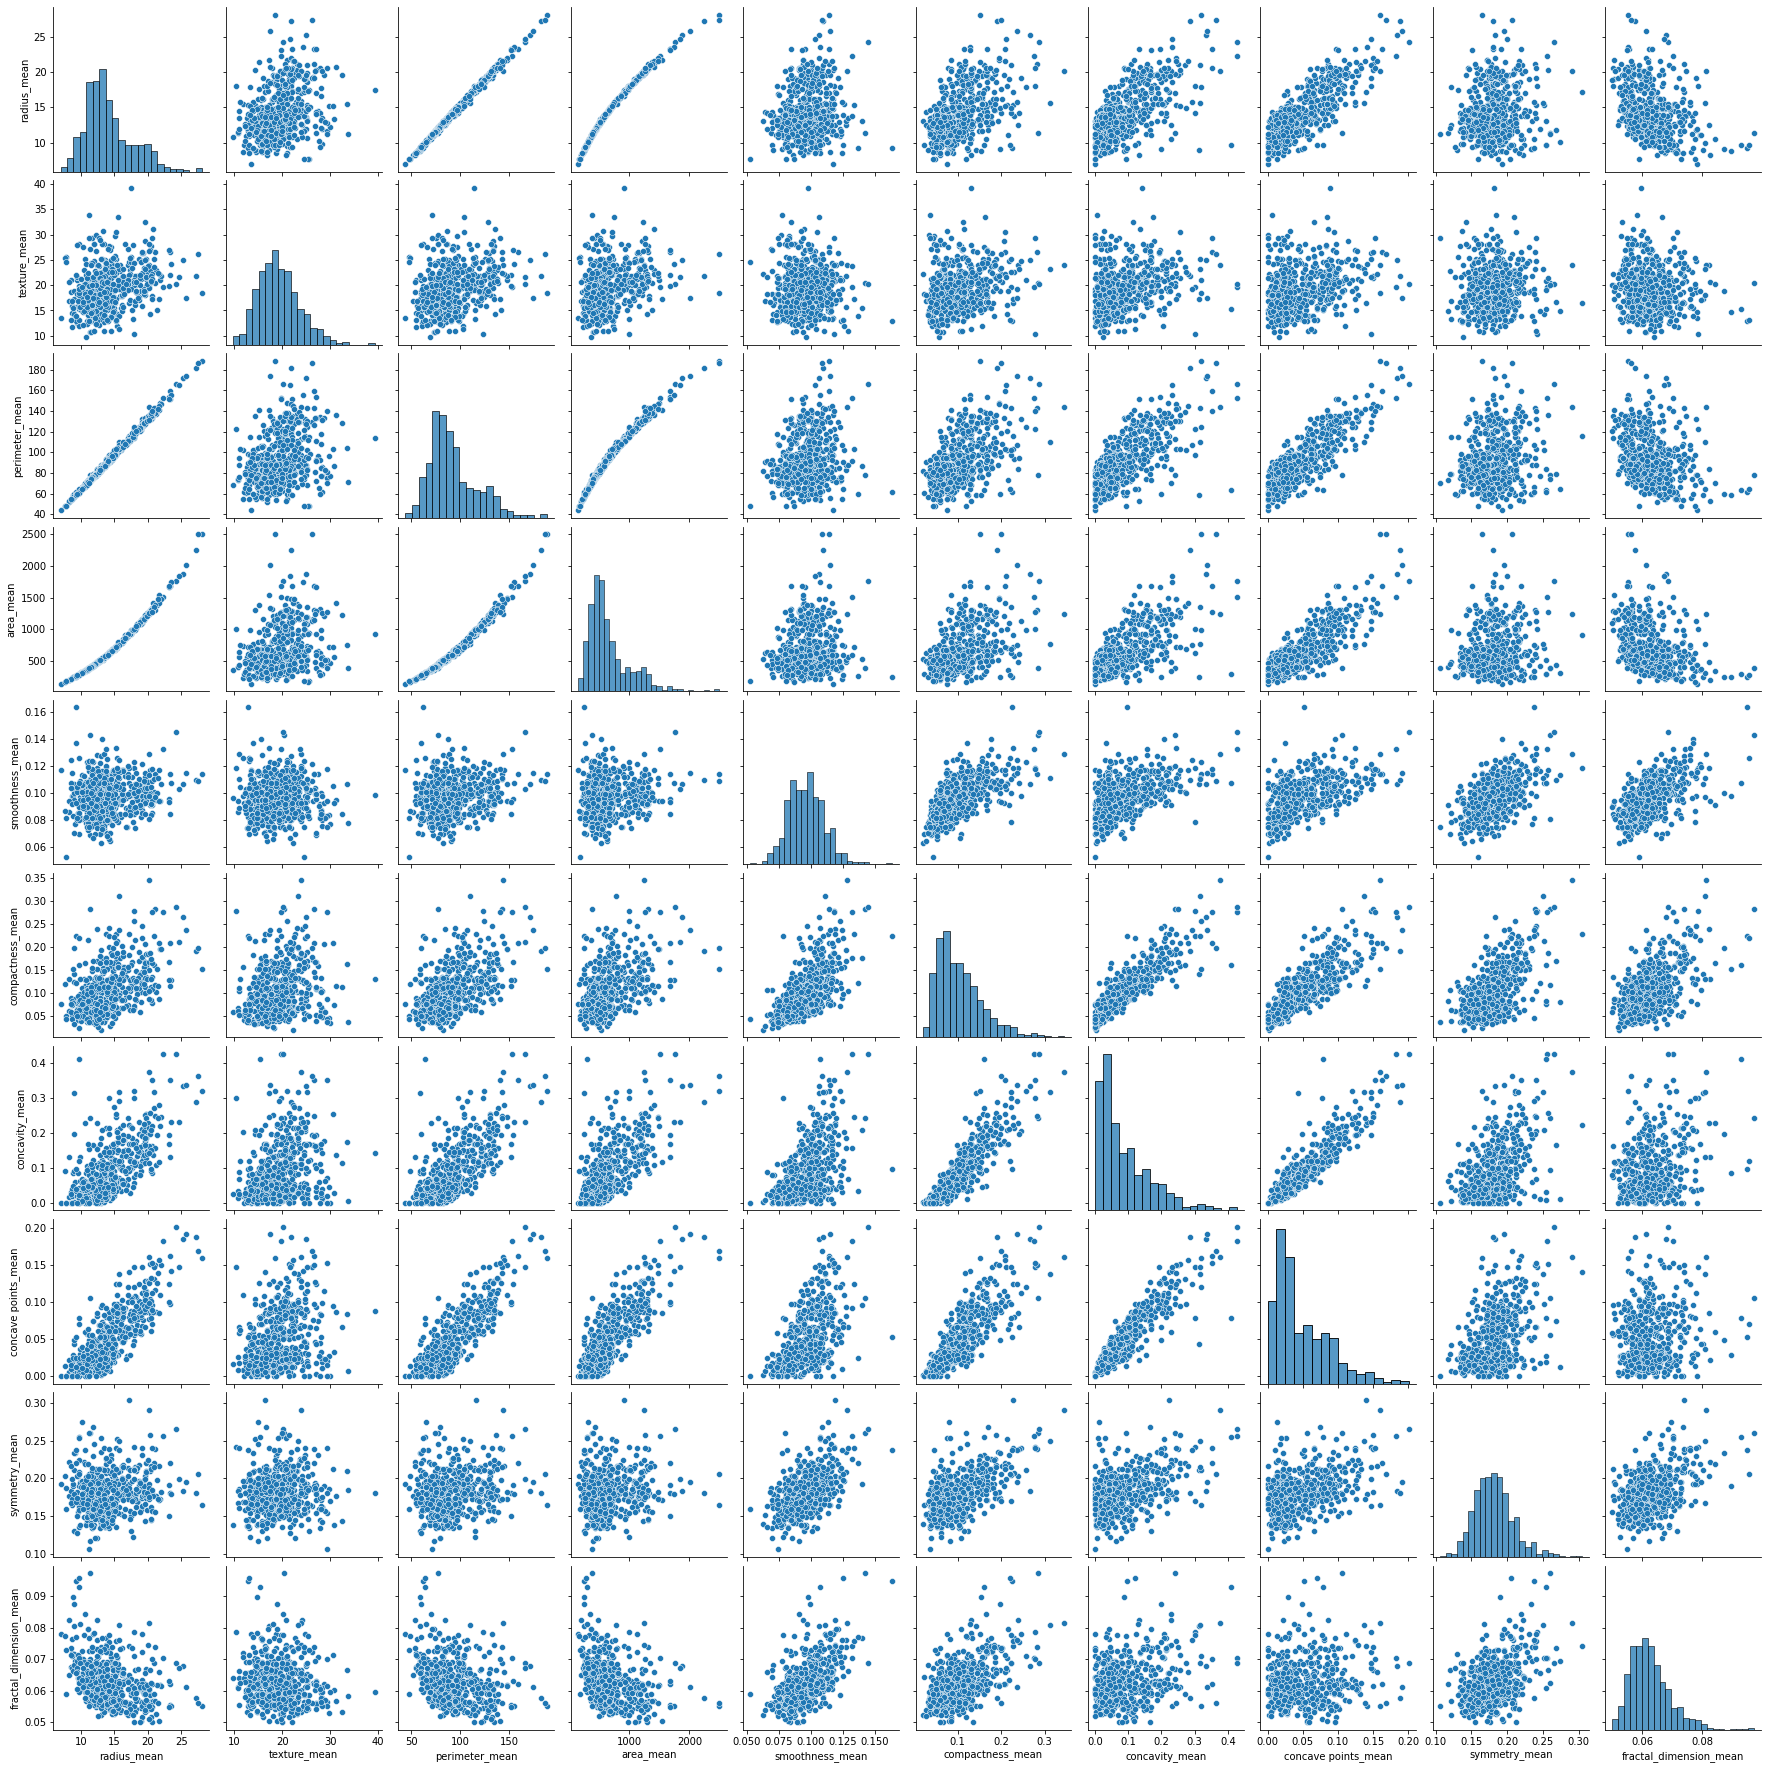

In [16]:
#-----------------------------------------------------
#Pega aqui el codigo sns.pairplot()
sns.pairplot(data=new_data_df[['radius_mean',
    'texture_mean',
    'perimeter_mean',
    'area_mean',
    'smoothness_mean',
    'compactness_mean',
    'concavity_mean',
    'concave points_mean',
    'symmetry_mean',
    'fractal_dimension_mean']])
plt.show()
#-----------------------------------------------------


De la matriz podrás observar relaciones lineales bastante evidentes entre:


*   `radius_mean`, `perimeter_mean` y `area_mean`
*   `compactness_mean`, `concavity_mean`, `concave_points_mean`

Sabemos que el perímetro y el área de un círculo, se calculan a partir del radio. Entonces, la relación entre las primeras tres variables es muy clara para nosotros.

3c) Elabora otro mapa de calor confirmar con los valores de correlación.


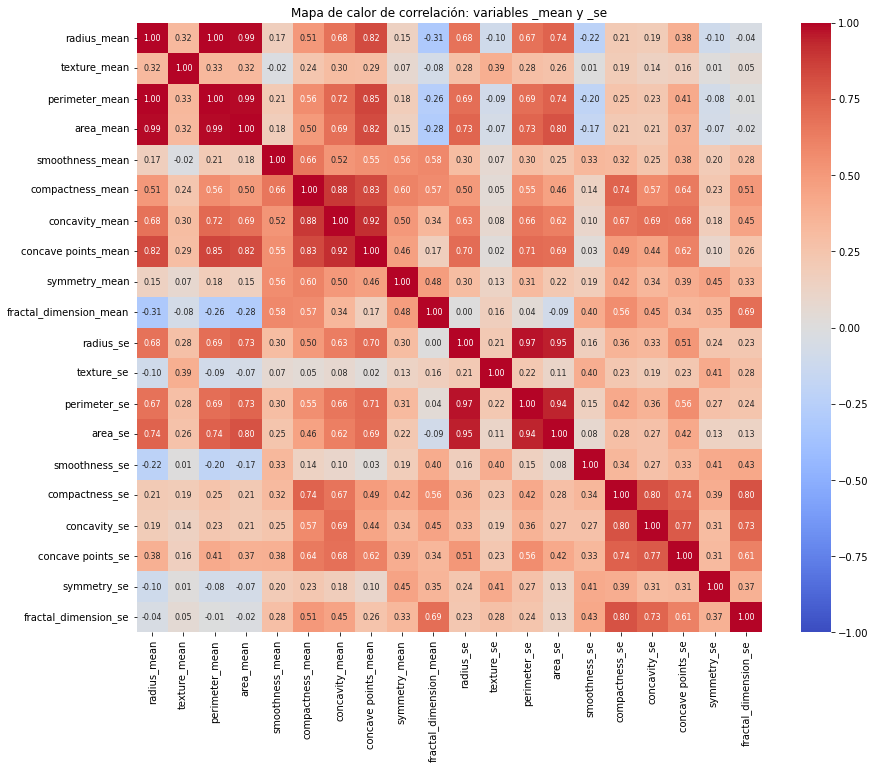

In [17]:
#-----------------------------------------------------
#Agrega codigo para el mapa de calor
corr_df = new_data_df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(14,11))
sns.heatmap(corr_df, annot=True, fmt='.2f', annot_kws={'size':8}, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Mapa de calor de correlación: variables _mean y _se')
plt.show()
#-----------------------------------------------------


3d) Después de observar los valores, nos quedaremos con sólo una variable de cada trío: `radius_mean` y `compactness_mean`. Elimina las restantes, no sólo del conjunto `_mean`, sino también de `_se`.

In [18]:
#-----------------------------------------------------
#escriba TODAS las columnas que seran eliminadas
columnas_a_eliminar=['perimeter_mean','area_mean','concavity_mean','concave points_mean',
                     'perimeter_se','area_se','concavity_se','concave points_se']
#-----------------------------------------------------



#-----------------------------------------------------
#Convierte new_data_df en Dataframe usando .DataFrame() de la libreria de pandas
new_data_df=pd.DataFrame(new_data_df.drop(columns=columnas_a_eliminar))
new_data_df
#-----------------------------------------------------


,diagnosis,radius_mean,texture_mean,smoothness_mean,compactness_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,smoothness_se,compactness_se,symmetry_se,fractal_dimension_se
id,,,,,,,,,,,,,
842302,M,17.99,10.38,0.11840,0.27760,0.2419,0.07871,1.0950,0.9053,0.006399,0.04904,0.03003,0.006193
842517,M,20.57,17.77,0.08474,0.07864,0.1812,0.05667,0.5435,0.7339,0.005225,0.01308,0.01389,0.003532
84300903,M,19.69,21.25,0.10960,0.15990,0.2069,0.05999,0.7456,0.7869,0.006150,0.04006,0.02250,0.004571
84348301,M,11.42,20.38,0.14250,0.28390,0.2597,0.09744,0.4956,1.1560,0.009110,0.07458,0.05963,0.009208
84358402,M,20.29,14.34,0.10030,0.13280,0.1809,0.05883,0.7572,0.7813,0.011490,0.02461,0.01756,0.005115
...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,0.11100,0.11590,0.1726,0.05623,1.1760,1.2560,0.010300,0.02891,0.01114,0.004239
926682,M,20.13,28.25,0.09780,0.10340,0.1752,0.05533,0.7655,2.4630,0.005769,0.02423,0.01898,0.002498
926954,M,16.60,28.08,0.08455,0.10230,0.1590,0.05648,0.4564,1.0750,0.005903,0.03731,0.01318,0.003892


Observa la distribución de las variables resultantes (deben ser 12, sin contar la columna de indice):

4a) Utilizando histogramas. Guarda en una variable (`skew_cols`) las que tengan marcado sesgo positivo. Para dar seguridad a tu selección, elige aquellas cuyo resultado de aplicar la función `skew()` sea mayor a 1.

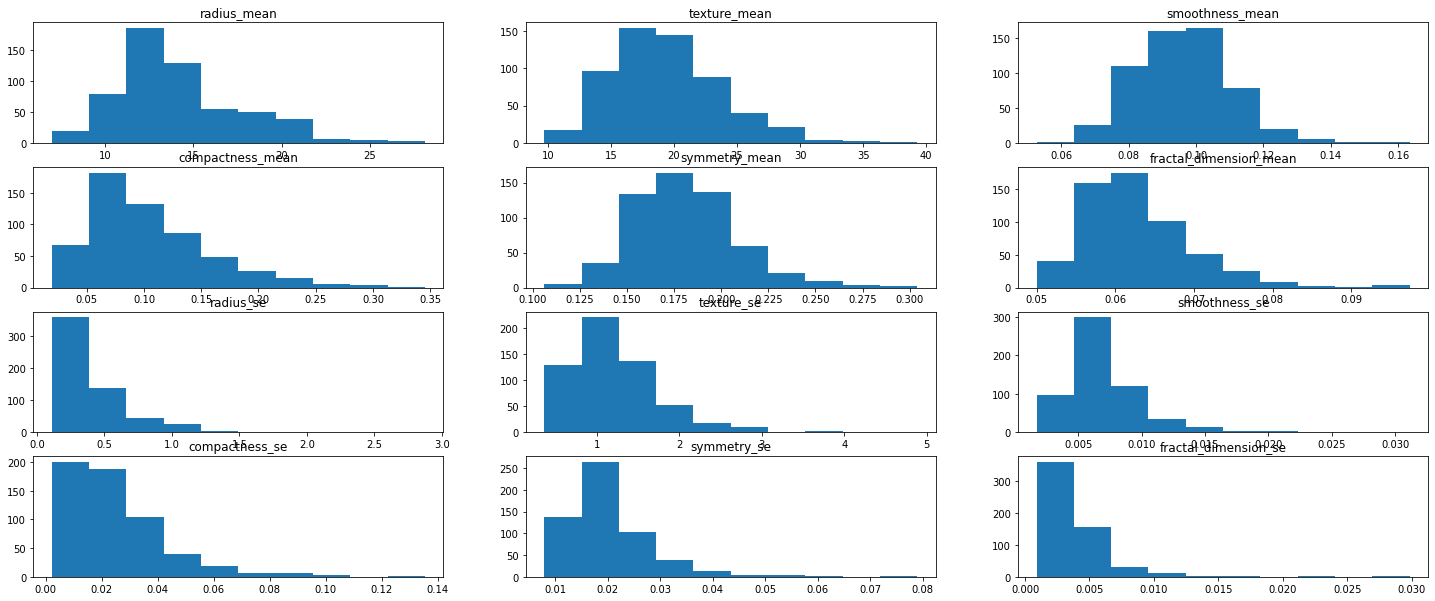

In [19]:
#EXPLICA CADA LINEA DE CODIGO
skew_cols_df=pd.DataFrame()                               # dataframe vacío donde se guardarán las variables con sesgo positivo
fig, axes =plt.subplots(4,3, figsize=(25,10)) #25 es el ancho, 10 altura   ---- 4,3 significa que seran  4 filas y 3 columnas
axes = axes.ravel()                                       # aplana la matriz 4x3 de ejes a una lista de 12 ejes para recorrerla con zip
num_cols = new_data_df.select_dtypes(include=np.number).columns.tolist()   # lista de columnas numéricas (excluye 'diagnosis')


for col, ax in zip (num_cols, axes):                      # empareja cada variable con un eje de la figura
  ax.hist(new_data_df[col])                               # dibuja el histograma de la variable
  ax.set(title = f'{col}', xlabel=None)                   # título = nombre de la variable; sin etiqueta en el eje x
  if new_data_df[col].skew()>1 : skew_cols_df[col] =new_data_df[col]   # si el sesgo es > 1 (sesgo positivo marcado), guarda la columna

skew_cols = skew_cols_df.columns.values                   # arreglo con los nombres de las variables sesgadas


In [20]:
skew_cols


<StringArray>
[      'compactness_mean', 'fractal_dimension_mean',              'radius_se',
             'texture_se',          'smoothness_se',         'compactness_se',
            'symmetry_se',   'fractal_dimension_se']
Length: 8, dtype: str

4b) Dibujando box plots de todas las variables. Guarda en una variable (`scale_cols`) aquellas que no se encuentren en el intervalo [0,1]


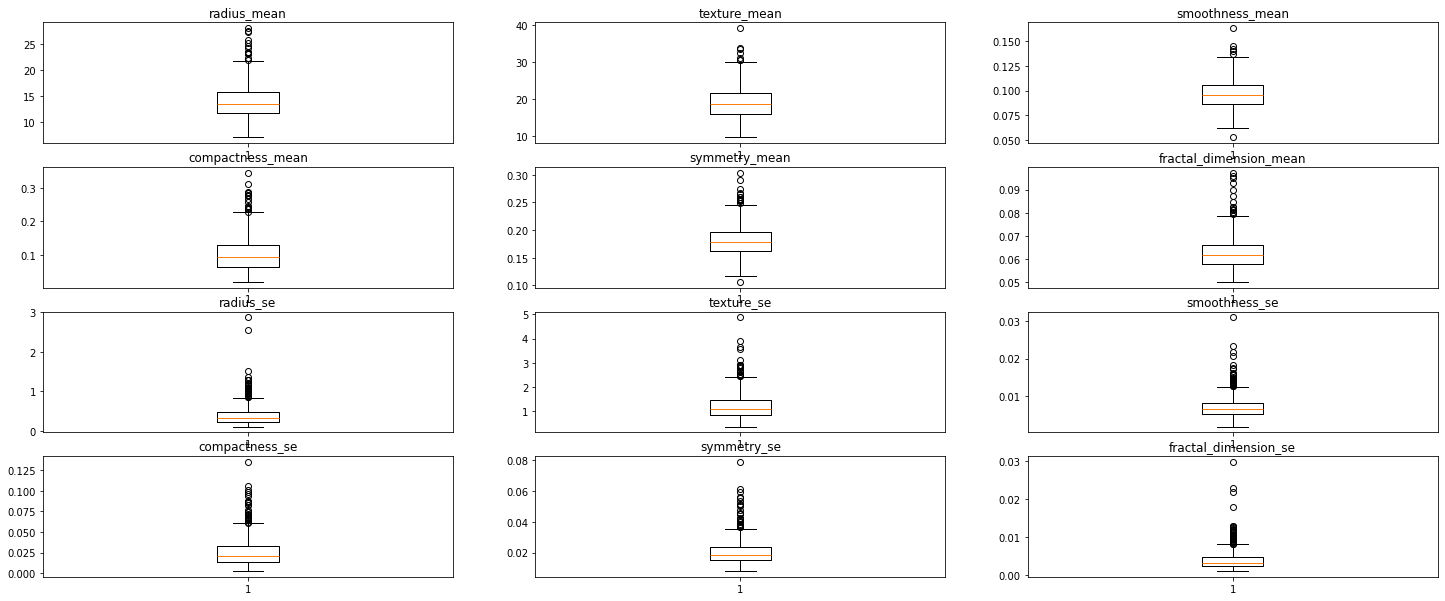

In [21]:
scale_cols_df=pd.DataFrame()
fig, axes = plt.subplots(4,3, figsize=(25,10))
axes = axes.ravel()

#-----------------------------------------------------
for col, ax in zip(new_data_df[num_cols], axes):

  ax.boxplot(new_data_df[col]) #COMPLETA LINEA DE CODIGO
  ax.set(title=f'{col}', xlabel=None)

  #COMPLETA EL IF
  if new_data_df[col].max() > 1 or new_data_df[col].min() < 0: scale_cols_df[col] = new_data_df[col]
#-----------------------------------------------------

scale_cols = scale_cols_df.columns.values


In [22]:
scale_cols


<StringArray>
['radius_mean', 'texture_mean', 'radius_se', 'texture_se']
Length: 4, dtype: str

Con todo el análisis anterior, estamos listos para generar un modelo *baseline* denominado `logr_model`. Para ello:

5a) Vuelve a leer el contenido del archivo, haz que el `id` sea el índice y separa las variables del dataframe: en `X` coloca los predictores y en `y` la variable de respuesta o salida (`diagnosis`). Divide el conjunto en entrenamiento y prueba (80:20) considerando el parámetro `random_state` con el valor de 1.

In [23]:
data_df = pd.read_csv('data.csv')

#-----------------------------------------------------
#AGREGA LINEA DE CODIGO PARA CONVERTIR COLUMNA "ID" EN INDICE
data_df.set_index('id', inplace=True)
#-----------------------------------------------------


In [24]:
X = data_df.copy() #Se crea copia del df


#-----------------------------------------------------
#                                  COMPLETA CODIGO
# se elimina variable Categorica "diagnosis" de (X), debido a se sera utilizada como variable de salida (y)
#-----------------------------------------------------
#Especifique la columna que desea eliminar
#Utilice el parametro axis=1, permitira eliminar la columna
#Guarde los cambios agregando el parametro inplace=True

X.drop('diagnosis', axis=1, inplace=True) #Caracteristica / variable Entrada
#-----------------------------------------------------

#-----------------------------------------------------
y = data_df['diagnosis'] #Objetivo /Variable salida
#-----------------------------------------------------
print('X:', X.shape, ' y:', y.shape)


X: (569, 30)  y: (569,)


In [25]:
#Libreria necesaria para realizar la particion del conjunto de datos
from sklearn.model_selection import train_test_split

# Se divide el conjunto en entrenamiento y prueba (80:20), es decir, 80% para Entrenamiento (train) y 20% para Prueba (test)
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=1)
print('Entrenamiento:', Xtrain.shape, ' Prueba:', Xtest.shape)


Entrenamiento: (455, 30)  Prueba: (114, 30)


5b) Prepara un transformador, denominado `preprocessing`, para borrar las columnas altamente correlacionadas (las 18 variables que se determinaron en los ejercicios previos) Asegúrate de incluir el parámetro `remainder='passthrough'` para mantener el resto de las variables.

In [26]:
#EXPLIQUE CADA LINEA DE CODIGO
# lista con las 18 variables altamente correlacionadas que se van a borrar: las 10 _worst y perimeter, area, concavity y concave points de _mean y _se
columnas_a_eliminar=['radius_worst','texture_worst','perimeter_worst','area_worst','smoothness_worst','compactness_worst','concavity_worst','concave points_worst','symmetry_worst','fractal_dimension_worst','perimeter_mean','area_mean','concavity_mean','concave points_mean','perimeter_se','area_se','concavity_se','concave points_se']

preprocessing = ColumnTransformer([          # ColumnTransformer: aplica transformaciones a columnas específicas
    ('num', 'drop', columnas_a_eliminar)]    # paso llamado 'num': la acción 'drop' elimina las columnas de la lista
   ,remainder='passthrough')                 # las columnas restantes (las 12 no listadas) pasan sin modificarse


5c) Entrena el modelo `logr_model` con el transformador `preprocessing` y  regresión logística.

Como la salida `y` está en términos de las etiquetas `'B'` y `'M'`, en lugar de 0 y 1, para evaluar el modelo en el conjunto de prueba deberás especificar la clase positiva. En el caso de la matriz de confusión, indica el orden de las etiquetas con `labels=['B','M']`, porque `'B'` es la clase negativa (ésta se especifica primero) y `'M'` la positiva. Para las métricas de *recall* y *precision*, utiliza el parámetro `pos_label='M'`. Como *accuracy* ocupa la suma de ambas clases y el total de las observaciones, no requiere ninguna especificación. Si quisieras omitir estos parámetros, tendrías que sustituir `'B'` por 0 y `'M'` por 1, previo a la construcción del modelo.

In [27]:
#EXPLIQUE CADA LINEA DE CODIGO

logr_model=make_pipeline(preprocessing, LogisticRegression())   # pipeline: primero 'preprocessing' (borra columnas) y luego el clasificador de regresión logística
logr_model.fit(Xtrain,ytrain)                                   # entrena: el preprocesamiento se ajusta con Xtrain y el modelo aprende los coeficientes
predictions=logr_model.predict(Xtest)                           # aplica el mismo preprocesamiento a Xtest y predice la clase ('B' o 'M')


print('matriz de confusion 1:\n',confusion_matrix(ytest,predictions,labels=['B','M']))   # filas = real, columnas = predicho; orden [B (negativa), M (positiva)]
print('recall    :\t',recall_score(ytest,predictions,pos_label='M'))      # VP/(VP+FN): proporción de malignos detectados
print('precision :\t',precision_score(ytest,predictions,pos_label='M'))   # VP/(VP+FP): de los predichos malignos, cuántos lo son realmente
print('accurancy :\t',accuracy_score(ytest,predictions))                  # (VP+VN)/total: proporción de aciertos


matriz de confusion 1:
 [[68  4]
 [10 32]]
recall    :	 0.7619047619047619
precision :	 0.8888888888888888
accurancy :	 0.8771929824561403


<font color=" ORANGE">INTERPRETE LOS RESULTADOS OBTENIDOS EN MATRIZ DE CONFUSION Y METRICAS

**Respuesta.** El conjunto de prueba tiene 114 observaciones (72 benignas y 42 malignas). La matriz de confusión del modelo baseline es:

| | Predicho B | Predicho M |
|---|---|---|
| **Real B** | 68 (verdaderos negativos) | 4 (falsos positivos) |
| **Real M** | 10 (falsos negativos) | 32 (verdaderos positivos) |

* **Accuracy = 0.877**: el modelo clasifica correctamente 100 de los 114 casos.
* **Precision = 0.889**: de los 36 casos que predijo como malignos, 32 realmente lo eran (4 falsas alarmas).
* **Recall = 0.762**: de los 42 tumores malignos reales detectó 32 y dejó pasar 10.

La exactitud es aceptable, pero en un diagnóstico de cáncer el error más costoso es el **falso negativo** (un tumor maligno clasificado como benigno). El recall de 0.76 indica que casi uno de cada cuatro tumores malignos no se detecta, por lo que este modelo baseline todavía es insuficiente para uso clínico.


Para generar un modelo `logr_model2` con transformación y escalamiento:

6a) Modifica el transformador anterior para, además del borrado de las columnas correlacionadas, aplicar la raíz cuadrada a los predictores con sesgo (previamente almacenados en `skew_cols`) y escalamiento *MinMax* a los predictores con escala mayor a 1 (previamente almacenados en `scale_cols`) Como no todos los predictores serán eliminados o transformados, asegúrate de incluir el parámetro `remainder='passthrough'`

In [28]:
#EXPLIQUE CADA LINEA DE CODIGO
preprocessing2 = ColumnTransformer([                         # transformador con tres pasos que se aplican a columnas distintas
    ('num0','drop', columnas_a_eliminar),                    # paso 1: elimina las 18 columnas correlacionadas
    ('num1',FunctionTransformer(np.sqrt),skew_cols),         # paso 2: raíz cuadrada a las variables con sesgo positivo (reduce el sesgo)
    ('num2',MinMaxScaler(),scale_cols)                       # paso 3: escala a [0,1] las variables fuera de ese intervalo
  ],remainder='passthrough')                                 # las demás columnas pasan sin cambios


6b) Entrena el modelo `logr_model2` con regresión logística, aplicando previamente el transformador modificado. Evalúa el modelo en el conjunto de prueba con las mismas métricas.

In [29]:
#ESCRIBA CODIGO AQUI
logr_model2=make_pipeline(preprocessing2, LogisticRegression())   # pipeline: preprocesamiento con transformación y escalamiento + regresión logística
logr_model2.fit(Xtrain,ytrain)                                    # entrena el modelo
predictions2=logr_model2.predict(Xtest)                           # predice sobre el conjunto de prueba

print('matriz de confusion 2:\n',confusion_matrix(ytest,predictions2,labels=['B','M']))
print('recall    :\t',recall_score(ytest,predictions2,pos_label='M'))
print('precision :\t',precision_score(ytest,predictions2,pos_label='M'))
print('accurancy :\t',accuracy_score(ytest,predictions2))


matriz de confusion 2:
 [[72  0]
 [11 31]]
recall    :	 0.7380952380952381
precision :	 1.0
accurancy :	 0.9035087719298246


<font color=" ORANGE">INTERPRETE LOS RESULTADOS OBTENIDOS EN MATRIZ DE CONFUSION Y METRICAS

**Respuesta.** La matriz de confusión del modelo 2 (con raíz cuadrada y escalamiento MinMax) es:

| | Predicho B | Predicho M |
|---|---|---|
| **Real B** | 72 (verdaderos negativos) | 0 (falsos positivos) |
| **Real M** | 11 (falsos negativos) | 31 (verdaderos positivos) |

* **Accuracy = 0.904** (antes 0.877): mejora de aproximadamente 2.6 puntos porcentuales.
* **Precision = 1.000** (antes 0.889): ningún tumor benigno fue clasificado como maligno.
* **Recall = 0.738** (antes 0.762): baja ligeramente; ahora se escapan 11 tumores malignos en lugar de 10.

La transformación y el escalamiento mejoran la exactitud y eliminan los falsos positivos, probablemente porque la regresión logística (que usa regularización L2 y un optimizador iterativo) es sensible a que las variables tengan escalas muy distintas y distribuciones sesgadas. Sin embargo, **no mejora la detección de tumores malignos** (el recall no sube), que es la métrica más importante en este problema. Además, la diferencia entre ambos modelos son solo unos pocos casos de un conjunto de prueba pequeño (114 observaciones), por lo que conviene confirmarla con validación cruzada.

**Nota técnica:** `radius_se` y `texture_se` están a la vez en `skew_cols` y en `scale_cols`. En un `ColumnTransformer` cada paso se aplica de forma independiente a la columna original, de modo que esas dos variables entran al modelo duplicadas (una con raíz cuadrada y otra con MinMax) y no con ambas transformaciones en secuencia. En la siguiente sección se corrige este detalle.



**6c) (Complemento) Corrección del traslape entre `skew_cols` y `scale_cols`.**

Para las variables que están en ambas listas (`radius_se`, `texture_se`) se aplica primero la raíz cuadrada y después el escalamiento MinMax, encadenándolos con `make_pipeline`. Las demás variables reciben solo su transformación correspondiente.


In [30]:

# variables en ambas listas, solo con sesgo y solo con escala
ambas      = [c for c in skew_cols if c in scale_cols]
solo_skew  = [c for c in skew_cols if c not in scale_cols]
solo_scale = [c for c in scale_cols if c not in skew_cols]
print('ambas     :', ambas)
print('solo skew :', solo_skew)
print('solo scale:', solo_scale)

preprocessing3 = ColumnTransformer([
    ('num0','drop', columnas_a_eliminar),
    ('sqrt', FunctionTransformer(np.sqrt), solo_skew),
    ('sqrt_minmax', make_pipeline(FunctionTransformer(np.sqrt), MinMaxScaler()), ambas),
    ('minmax', MinMaxScaler(), solo_scale)
  ],remainder='passthrough')

logr_model3 = make_pipeline(preprocessing3, LogisticRegression())
logr_model3.fit(Xtrain,ytrain)
predictions3 = logr_model3.predict(Xtest)

print()
print('columnas que entran al modelo -> modelo 2:', preprocessing2.fit_transform(Xtrain).shape[1], '| modelo 3:', preprocessing3.fit_transform(Xtrain).shape[1])
print('matriz de confusion 3:\n',confusion_matrix(ytest,predictions3,labels=['B','M']))
print('recall    :\t',recall_score(ytest,predictions3,pos_label='M'))
print('precision :\t',precision_score(ytest,predictions3,pos_label='M'))
print('accurancy :\t',accuracy_score(ytest,predictions3))


ambas     : ['radius_se', 'texture_se']
solo skew : ['compactness_mean', 'fractal_dimension_mean', 'smoothness_se', 'compactness_se', 'symmetry_se', 'fractal_dimension_se']
solo scale: ['radius_mean', 'texture_mean']

columnas que entran al modelo -> modelo 2: 14 | modelo 3: 12
matriz de confusion 3:
 [[72  0]
 [11 31]]
recall    :	 0.7380952380952381
precision :	 1.0
accurancy :	 0.9035087719298246



Con la corrección, el modelo recibe 12 variables (en lugar de 14 columnas con duplicados) y las métricas son **idénticas** a las del modelo 2 (accuracy 0.904, precision 1.000, recall 0.738). Es decir, el traslape no afectó el desempeño en este caso, pero la versión corregida es más limpia y evita redundancia en los predictores.


<font color=" ORANGE">CONCLUSION DE LA PRACTICA

**Conclusión.**

1. **Datos.** El dataset Breast Cancer Wisconsin tiene 569 observaciones (357 benignas, 62.7 %, y 212 malignas, 37.3 %), 30 predictores numéricos y ningún valor faltante. Las clases están moderadamente desbalanceadas.
2. **Multicolinealidad.** Las variables `_mean`, `_se` y `_worst` de una misma característica están muy correlacionadas, y radio, perímetro y área son casi redundantes (correlación cercana a 1). Se eliminaron 18 de las 30 variables y quedaron 12 predictores, lo que reduce la redundancia sin perder las características principales.
3. **Preprocesamiento.** Se identificaron 8 variables con sesgo positivo (`skew() > 1`) y 4 fuera del intervalo [0,1] (`radius_mean`, `texture_mean`, `radius_se`, `texture_se`), que se trataron con raíz cuadrada y escalamiento MinMax respectivamente.
4. **Modelos.** El baseline logró accuracy 0.877, precision 0.889 y recall 0.762. El modelo con transformación y escalamiento subió a accuracy 0.904 y precision 1.000, pero su recall bajó a 0.738.
5. **Interpretación.** El preprocesamiento mejora la exactitud y elimina los falsos positivos, pero ningún modelo detecta de forma confiable todos los tumores malignos (10 y 11 falsos negativos). En un problema médico se debe priorizar el recall, por lo que sería recomendable explorar `class_weight='balanced'`, ajustar el umbral de decisión, usar validación cruzada o probar la alternativa con PCA planteada en la práctica.
